# Image Segmentation

**EA234503 Visi Komputer – Evaluasi CPMK 3**

| | |
|---|---|
| Nama | *Royan Harits Yustanto* |
| NRP | *5054241022* |
| Train Dataset | Panoptic Indoor Segmentation **v5** (Roboflow Universe, `panopticindoor/panoptic-indoor-segmentation`) |
| Test set mandiri | `mycapture`: 59 foto ruangan nyata dari HP, annotate di Roboflow |
| Model | YOLO11s-seg (one-stage CNN), Mask R-CNN R50-FPN v2 (two-stage CNN), Mask2Former Swin-T (transformer) |

**Ringkasan hasil (mask AP, data latih 100%)**

| Model | valid v5 | test v5 | mycapture |
|---|---|---|---|
| YOLO11s-seg | 0,212 | 0,089 | 0,070 |
| Mask R-CNN | 0,186 | 0,105 | 0,090 |
| **Mask2Former** | **0,288** | **0,165** | **0,140** |

- Mask2Former terbaik di semua set evaluasi dan semua jumlah data.
- Semua model turun 14–32% dari test v5 ke foto sendiri (domain shift).
- Menambah data menaikkan AP Mask R-CNN, hampir tidak berpengaruh ke Mask2Former (50% → 100%), dan justru menurunkan
  AP YOLO karena *catastrophic forgetting*.
- Kegagalan utama di foto sendiri adalah salah kelas atau tidak terdeteksi (kursi berderet dikira tangga, piring dikira
  panci), bukan mask yang kasar.

## 1. Hipotesis


### 1.1 Hipotesis awal: kualitas data 

> Secara keseluruhan **semua model akan berperforma buruk**, apa pun arsitekturnya, karena:
 1. **Kualitas dataset v5 rendah.** Train hanya 397 gambar untuk 74 kelas, ada kelas typo/duplikat
    (`scissor`/`scissors`, `wall`/`wall-other-merged`, `st-`), dan 8 kelas tidak punya contoh train sama sekali.
 2. **Ketimpangan data**, baik antar-kelas (`wall-other-merged` 756 instance, banyak kelas hanya 1–5) maupun
    antar-split (handbag 5 di train vs 125 di test, dining table 4 vs 112, wallet 197 vs 5).
    Akibatnya AP di test v5 diperkirakan jauh di bawah AP valid.
 3. **kondisi foto data train yang kurang realistis** (dimana banyak data train yang sepertinya diambil dari internet yang kurang mencerminkan pencahayaan dunia nyata.)
    Prediksi terukurnya: **AP mycapture < AP test v5** untuk semua model.

### 1.2 Hipotesis perbandingan model

 1. **Model terbaik: Mask2Former.** Arsitekturnya transformer dan dirancang khusus untuk segmentasi, sedangkan
    seri YOLO lebih mengutamakan kecepatan inferensi (real-time).
 2. **Model terburuk: Mask R-CNN.**
 3. **Kelas yang akan bagus:** dinding (`wall-other-merged`) karena porsinya paling banyak di data train,
    serta `chair` dan `person` karena contohnya di train jauh lebih banyak dibanding jumlahnya di test set saya.

## 2. Tahapan yang sudah dilakukan

### 2.1 Memahami dataset v5 (`01_download_dataset.ipynb`)

- Dataset v5 di-download dalam format COCO segmentation lewat Roboflow API, lalu dihitung statistik per kelas
  (`outputs/class_stats_v5.csv`).

| Hal | Nilai |
|---|---|
| Gambar | train 397, valid 166, test 359 |
| Anotasi | train 4.479, valid 2.022, test 5.344 |
| Kelas | 74 |
| Kelas tanpa contoh train | 9: flower, hair drier, keyboard, mouse, scissor, scissors, teddy bear, toaster, toothbrush |
| Objek terbanyak per gambar | 129 (test) |
| Ketidakcocokan train vs test | handbag 5 vs 125, dining table 4 vs 112, curtain 3 vs 107, wallet 197 vs 5, box 95 vs 1 |


### 2.2 Desain eksperimen

- **Variabel Berdasarkan NRP:** jumlah data latih 25% / 50% / 100%, hanya diterapkan pada split `train`.
  `valid` (166) dan `test` v5 (359) tetap utuh.
- Subset dibuat **bertingkat** (25% ⊂ 50% ⊂ 100%, seed 42): 99 / 198 / 397 gambar. Gambar yang memuat kelas paling
  jarang diambil lebih dulu, sehingga ketiga subset sama-sama memuat 65 dari 74 kelas (9 kelas sisanya memang tidak ada di train).
- Checkpoint dipilih dengan **valid**. Dua test set (test v5 dan mycapture) hanya dipakai untuk laporan, dan
  **semua model** dievaluasi di keduanya.

### 2.3 Membuat test set sendiri: mycapture 

- **Pengambilan foto:** 59 foto dengan HP (POCO X7 Pro, 4096×3072 (4:3), EXIF utuh) di rumah, kamar kos, lingkungan tc, 
  dan ballroom. Nama file diseragamkan menjadi `mycapture_NN.jpg` (`rename_mycapture.py`); nama asli, waktu foto, dan kondisi
  tercatat di `rename_log.csv`.
- **Kondisi sulit:** 25 dari 59 foto (backlight, redup, penuh, saling menutupi, sudut ekstrem).
- **Anotasi di Roboflow** (project `room_mycapture`, Instance Segmentation) memakai polygon, dengan nama kelas persis
  seperti v5. Proses anotasi dilakukan manual dan tidak menggunakan auto label. 
  - Satu objek satu anotasi dan bagian yang tertutup tidak dianotasi.
  - Benda yang tidak memiliki label tapi memiliki bentuk serupa, diberi label yang paling mirip. Seperti stool → `chair`, monitor → `tv`, toples/galon → `bottle`, kardus → `box`.
  - Benda yang tidak punya kelas dibiarkan tanpa label.
  - Kerumunan kursi jauh yang tidak bisa dipisah diberi satu polygon `chair-crowd`, yang diperlakukan sebagai area
- **Export:** versi 1, Auto-Orient + Resize Stretch 640×480, tanpa augmentasi.
  Roboflow menaruh 1 foto di split valid dan 58 di test. Keduanya digabung menjadi satu test set.

### 2.4 Pemilihan model

| Model | Keluarga | Mekanisme mask |
|---|---|---|
| YOLO11s-seg | one-stage CNN | 32 *prototype mask* beresolusi 1/4 input, dikombinasikan dengan koefisien per deteksi lalu dipotong oleh box |
| Mask R-CNN R50-FPN v2 | two-stage CNN | proposal (RPN) → RoIAlign → mask **28×28 per RoI**, lalu di-resize ke ukuran box |
| Mask2Former Swin-T | transformer | 100 *query* masing-masing memprediksi satu kelas + satu mask (1/4 input), tanpa box/proposal dan tanpa NMS |

Ketiganya memakai bobot pretrained COCO. Perbedaan penting: Ultralytics otomatis memakai ulang bobot kepala klasifikasi
YOLO untuk kelas yang namanya sama dengan kelas COCO, sedangkan Mask R-CNN dan Mask2Former memulai kepala klasifikasinya dari nol.

### 2.5 Training di Kaggle (`02_train_yolo11seg.ipynb`, `03_train_maskrcnn.ipynb`, `04_train_mask2former.ipynb`)

- GPU Kaggle Tesla T4, input sisi panjang 640, **batas 40 menit per run** (3 run × 40 menit = 2 jam GPU per model).
  Jadwal learning rate ikut menyesuaikan batas waktu supaya tetap selesai turun.
- Evaluasi **sama untuk semua model**: pycocotools (mask & box AP), `MAX_DET=200` (ada gambar berisi 129 objek),
  `SCORE_THRESH=0.05`.
- Sebelum dijalankan di Kaggle, ketiga notebook diuji di laptop: smoke test, dan uji overfit 12 gambar
  (Mask R-CNN mencapai AP 0,53, Mask2Former 0,97), yang membuktikan pipeline dan label benar.

| Model | Waktu train 25 / 50 / 100% (menit) | Epoch dijalankan | Best epoch |
|---|---|---|---|
| YOLO11s-seg | 3,7 / 11,2 / 22,8 | 33 / 88 / 114 | 3 / 42 / 84 |
| Mask R-CNN | 16,4 / 23,9 / 40,3 | 40 / 40 / 40 | 30 / 32 / 32 |
| Mask2Former | 24,8 / 39,4 / 40,5 | 55 / 50 / 28 | 35 / 30 / 15 |

- Total waktu GPU (train + eval): YOLO ±40 menit, Mask R-CNN ±86 menit, Mask2Former ±110 menit, semuanya di bawah 2 jam.
  Rincian ada di `*/gpu_log.csv`, dan log training per epoch di `*/<run>/results.csv`.
- **Kendala:**
  - Percobaan pertama Mask2Former gagal karena CUDA out of memory saat evaluasi test v5 (gambar 3024×3398).
    Fungsi prediksi diperbaiki, lalu training diulang.
  - Split mycapture belum tersedia saat training, jadi evaluasinya dilakukan di notebook ini dari bobot yang tersimpan.
  - File `results.csv` sempat rusak karena bug pencatat. Bug diperbaiki dan isi datanya tidak berubah.

### 2.6 Temuan awal dari test v5

- Mask2Former unggul di semua fraksi. AP test v5 jauh di bawah AP valid untuk ketiga model.
- YOLO di test v5 justru turun saat data ditambah (0,138 → 0,089). Run 25% berhenti di best epoch 3, sehingga
  hampir sama dengan model COCO. Dengan training lebih lama, kelas COCO "terlupakan" (*catastrophic forgetting*),
  terutama `mouse`, `keyboard`, dan `scissors` yang tidak punya contoh train di v5.
- v5 juga tidak konsisten antar-split: kardus dilabeli `box` di train/valid, tetapi kebanyakan `cardboard` di test.

## 3. Persiapan inferensi

Semua langkah di bawah ini **hanya inferensi dan evaluasi**, tanpa training ulang. Bobot model diambil dari hasil training
di Kaggle (`yolo11s/`, `maskrcnn/`, `mask2former/`), lalu dijalankan di laptop (RTX 3050 6 GB).
Kode model ada di `lib/models.py` dan dibuat **sama persis** dengan notebook training, supaya angkanya bisa dibandingkan.

In [1]:
# Pasang library yang belum ada (sekali saja)
import importlib.util
for mod, pkg in [("pycocotools", "pycocotools"), ("ultralytics", "ultralytics==8.4.216")]:
    if importlib.util.find_spec(mod) is None:
        %pip install -q {pkg}

In [2]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("lib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from common import *          # konversi COCO, evaluasi pycocotools (sama dengan saat training)
import models as MD           # load bobot + inferensi ketiga model
import analysis as AN         # grafik, statistik per foto, visualisasi
AN.setup_style()
pd.set_option("display.precision", 3)

V5_DIR = "data/panoptic-indoor-v5-coco"
MYCAP_DIR = "data/room_mycapture.v1i.coco-segmentation"     # export Roboflow versi 1 (COCO Segmentation)
OUT = "hasil_lokal"
MYCAP_MERGE = {"nox": "box"}     # 1 anotasi typo di foto #46
MAX_DET, SCORE_THRESH = 200, 0.05  # sama dengan saat training/evaluasi di Kaggle
MODELS, FRACS = list(AN.COLORS), AN.FRACS
RERUN = False                      # True = jalankan ulang inferensi walaupun hasil prediksi sudah tersimpan
print("device:", MD.DEVICE, "|", gpu_name())

device: cuda | NVIDIA GeForce RTX 3050 6GB Laptop GPU


### 3.1 Menyiapkan dua test set

Kelas dari kedua test set dipetakan ke **74 kelas v5** berdasarkan nama (urutan kelas dicek sama dengan saat training).
Polygon berkelas `chair-crowd` disimpan sebagai `chair` dengan `iscrowd=1`, sehingga pycocotools memperlakukannya sebagai
area abaikan.

In [3]:
classes = canonical_classes(os.path.join(V5_DIR, "train", "_annotations.coco.json"))
assert classes == load_json("mask2former/data_canonical/classes.json"), "urutan kelas tidak sama dengan saat training"

GT = {"test_v5": f"{OUT}/data/test_v5.json", "mycapture": f"{OUT}/data/mycapture.json"}
to_canonical_coco([os.path.join(V5_DIR, "test")], classes, GT["test_v5"], None, f"{OUT}/data/resized", max_side=10**9)
mc_splits = [os.path.join(MYCAP_DIR, s) for s in ("train", "valid", "test")
             if os.path.exists(os.path.join(MYCAP_DIR, s, "_annotations.coco.json"))]
to_canonical_coco(mc_splits, classes, GT["mycapture"], MYCAP_MERGE, f"{OUT}/data/resized")
gt = {k: load_json(p) for k, p in GT.items()}

pd.DataFrame([{"test set": k, "foto": len(c["images"]),
               "anotasi": sum(not a["iscrowd"] for a in c["annotations"]),
               "area crowd": sum(a["iscrowd"] for a in c["annotations"]),
               "kelas terpakai": len({a["category_id"] for a in c["annotations"]}),
               "ukuran gambar": ", ".join(sorted({f"{i['width']}x{i['height']}" for i in c["images"]})[:3])}
              for k, c in gt.items()]).set_index("test set")

,foto,anotasi,area crowd,kelas terpakai,ukuran gambar
test set,,,,,
test_v5,359,5344,0,69,"1000x1000, 1000x1250, 1000x1500"
mycapture,59,886,12,53,640x480


### 3.2 Seberapa mirip isi mycapture dengan data latih?

Tabel ini membandingkan jumlah objek per kelas di mycapture dengan jumlahnya di **train v5** (yang dipakai model belajar).
Kelas dengan contoh train sedikit atau nol diperkirakan sulit.

In [4]:
stats = pd.read_csv("outputs/class_stats_v5.csv").set_index("class")
cnt_mc = pd.Series([classes[a["category_id"] - 1] for a in gt["mycapture"]["annotations"] if not a["iscrowd"]]).value_counts()
cls_tab = pd.DataFrame({"mycapture": cnt_mc,
                        "train v5": stats["instances_train"].reindex(cnt_mc.index).fillna(0).astype(int),
                        "test v5": stats["instances_test"].reindex(cnt_mc.index).fillna(0).astype(int)})
print(f"{len(cls_tab)} kelas dipakai di mycapture; "
      f"{(cls_tab['train v5'] == 0).sum()} di antaranya tidak punya contoh train sama sekali: "
      f"{', '.join(cls_tab.index[cls_tab['train v5'] == 0])}")
print(f"{(cls_tab['train v5'] < 10).sum()} kelas punya < 10 contoh train.")
cls_tab.T

53 kelas dipakai di mycapture; 4 di antaranya tidak punya contoh train sama sekali: scissors, toothbrush, mouse, keyboard
19 kelas punya < 10 contoh train.


,box,chair,bottle,wall-other-merged,wall-brick,light,window-other,floor-other-merged,plate,cabinet-merged,...,mouse,toilet,keyboard,dining table,wallet,paper-merged,refrigerator,mirror-stuff,blanket,window-blind
mycapture,171,104,91,61,39,33,30,28,23,20,...,2,2,2,2,1,1,1,1,1,1
train v5,95,217,62,756,48,41,90,261,86,47,...,0,2,0,4,197,1,2,8,19,29
test v5,1,353,58,650,25,295,144,239,104,110,...,8,14,7,112,5,51,5,34,13,71


### 3.3 Kondisi foto

Label kondisi diambil dari kolom `kondisi` di `rename_log.csv` (satu foto bisa punya lebih dari satu label).

In [5]:
cond = AN.load_conditions("rename_log.csv", gt["mycapture"])
labels = sorted({c for s in cond.values() for c in s})
pd.Series({c: sum(c in s for s in cond.values()) for c in labels}, name="jumlah foto").to_frame().T

,backlight,normal,penuh,redup,saling menutupi,sudut ekstrem
jumlah foto,7,34,15,1,14,1


## 4. Inferensi

Setiap model × setiap jumlah data latih (25/50/100%) dijalankan pada **mycapture**. Model 100% juga dijalankan ulang pada
**test v5** untuk membuktikan bahwa hasil di laptop sama dengan hasil di Kaggle. Hasil prediksi disimpan di
`hasil_lokal/preds/`, jadi kalau notebook dijalankan lagi inferensi tidak diulang (kecuali `RERUN = True`).

In [6]:
def pred_path(key, tag, split):
    return f"{OUT}/preds/{key}_{tag}_{split}.json"

jobs = [(k, t, s) for k in MODELS for t in FRACS for s in ["mycapture"] + (["test_v5"] if t == "100pct" else [])]
infer_log = []
for key in MODELS:
    for tag in FRACS:
        todo = [s for (k, t, s) in jobs if k == key and t == tag and (RERUN or not os.path.exists(pred_path(k, t, s)))]
        if not todo:
            continue
        model = MD.load_model(key, f"{key}/{tag}", classes, score_thresh=SCORE_THRESH, max_det=MAX_DET)
        for split in todo:
            t0 = time.time()
            preds = model.predict_coco(gt[split])
            save_json(preds, pred_path(key, tag, split))
            infer_log.append({"model": key, "run": tag, "split": split, "foto": len(gt[split]["images"]),
                              "detik": round(time.time() - t0, 1)})
            print(f"{key:12s} {tag} {split:10s} {len(preds):6d} prediksi  {infer_log[-1]['detik']:.0f} detik")
        del model
        MD.free_gpu()

preds = {(k, t, s): load_json(pred_path(k, t, s)) for (k, t, s) in jobs}
pd.DataFrame(infer_log) if infer_log else print("Semua prediksi sudah tersimpan, inferensi tidak diulang.")

Semua prediksi sudah tersimpan, inferensi tidak diulang.


### 4.1 Cek reproduksi: hasil laptop vs Kaggle

Kalau bobot dan kode inferensi benar, mask AP di test v5 harus sama dengan angka dari Kaggle.

In [7]:
kaggle = pd.concat([pd.read_csv(f"{k}/metrics.csv").assign(model_key=k) for k in MODELS], ignore_index=True)
rows = []
for key in MODELS:
    s, _ = coco_evaluate(GT["test_v5"], preds[(key, "100pct", "test_v5")], MAX_DET)
    k = kaggle[(kaggle.model_key == key) & (kaggle.run == "100pct") & (kaggle.split == "test_v5")].iloc[0]
    rows.append({"model": AN.LABELS[key], "mask AP laptop": s["AP"], "mask AP Kaggle": k.mask_AP,
                 "selisih": s["AP"] - k.mask_AP})
pd.DataFrame(rows).set_index("model").round(4)

,mask AP laptop,mask AP Kaggle,selisih
model,,,
YOLO11s-seg,0.089,0.089,1.000e-04
Mask R-CNN,0.105,0.105,0.000e+00
Mask2Former,0.165,0.165,-0.000e+00


## 5. Hasil

### 5.1 Evaluasi mycapture

Metrik sama dengan training: **mask AP COCO** (rata-rata IoU 0,50–0,95), AP50, AP75, dan AP per ukuran objek.

In [8]:
rows = []
for key in MODELS:
    for tag in FRACS:
        segm, per_cls = coco_evaluate(GT["mycapture"], preds[(key, tag, "mycapture")], MAX_DET, "segm")
        box, _ = coco_evaluate(GT["mycapture"], preds[(key, tag, "mycapture")], MAX_DET, "bbox")
        r = {"model_key": key, "run": tag, "split": "mycapture"}
        r.update({f"mask_{k}": v for k, v in segm.items()})
        r.update({f"box_{k}": v for k, v in box.items()})
        rows.append(r)
local = pd.DataFrame(rows)
local.to_csv(f"{OUT}/metrics_mycapture.csv", index=False)

allm = pd.concat([kaggle[kaggle.split.isin(["valid", "test_v5"])], local], ignore_index=True)
allm["model"] = allm.model_key.map(AN.LABELS)
local.assign(model=local.model_key.map(AN.LABELS)).set_index(["model", "run"])[
    ["mask_AP", "mask_AP50", "mask_AP75", "mask_APs", "mask_APm", "mask_APl", "box_AP"]].round(3)

mask_AP  mask_AP50  mask_AP75  mask_APs  mask_APm  \
model       run                                                         
YOLO11s-seg 025pct    0.107      0.146      0.116     0.015     0.120   
            050pct    0.065      0.103      0.069     0.022     0.047   
            100pct    0.070      0.109      0.072     0.022     0.050   
Mask R-CNN  025pct    0.044      0.086      0.041     0.008     0.068   
            050pct    0.061      0.109      0.060     0.007     0.051   
            100pct    0.090      0.144      0.104     0.011     0.056   
Mask2Former 025pct    0.122      0.179      0.132     0.019     0.093   
            050pct    0.135      0.206      0.134     0.019     0.103   
            100pct    0.140      0.240      0.127     0.032     0.089   

                    mask_APl  box_AP  
model       run                       
YOLO11s-seg 025pct     0.128   0.113  
            050pct     0.106   0.068  
            100pct     0.118   0.081  
Mask R-CNN  025pct     0.076   0.055  
            050pct     0.126   0.070  
            100pct     0.190   0.093  
Mask2Former 025pct     0.205   0.122  
            050pct     0.219   0.137  
            100pct     0.270   0.142

### 5.2 Jumlah data latih 25% / 50% / 100%

Tabel dan grafik di bawah menunjukkan mask AP ketiga model di ketiga set evaluasi. Angka valid dan test v5 berasal dari
Kaggle (`*/metrics.csv`), angka mycapture dari evaluasi di atas.

valid               test_v5               mycapture              
            025pct 050pct 100pct  025pct 050pct 100pct    025pct 050pct 100pct
model                                                                         
Mask R-CNN   0.120  0.158  0.186   0.062  0.090  0.105     0.044  0.061   0.09
Mask2Former  0.266  0.314  0.288   0.146  0.164  0.165     0.122  0.135   0.14
YOLO11s-seg  0.129  0.187  0.212   0.138  0.092  0.089     0.107  0.065   0.07

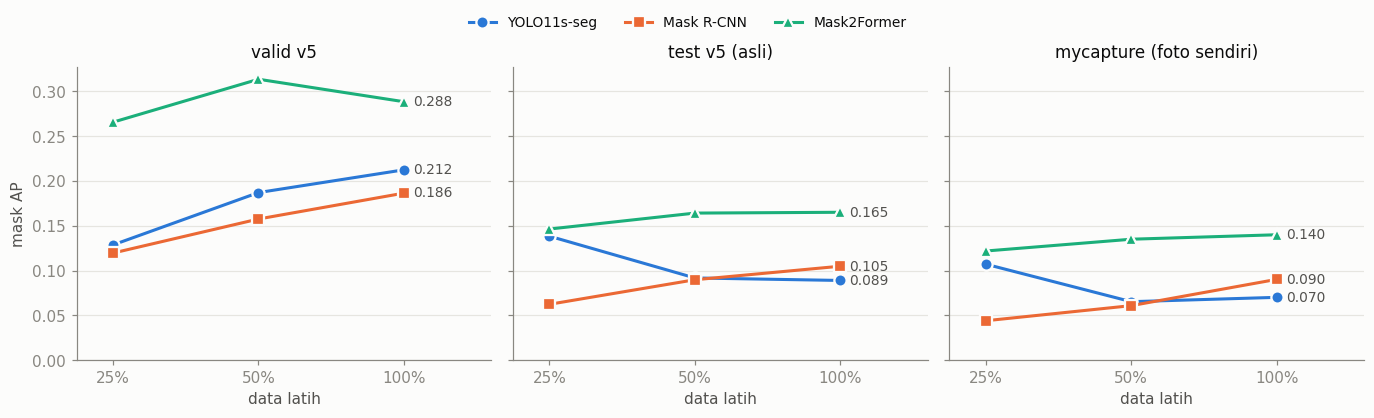

In [9]:
tab = allm.pivot_table(index="model", columns=["split", "run"], values="mask_AP").reindex(
    columns=pd.MultiIndex.from_product([["valid", "test_v5", "mycapture"], FRACS]))
display(tab.round(3))
fig = AN.plot_fraction_lines(allm, ["valid", "test_v5", "mycapture"],
                             titles={"valid": "valid v5", "test_v5": "test v5 (asli)", "mycapture": "mycapture (foto sendiri)"})
fig.savefig(f"{OUT}/grafik_ap_vs_data.png", dpi=150, bbox_inches="tight")

### 5.3 Domain shift: test v5 vs mycapture

split               mycapture  test_v5  selisih  perubahan %
model       run                                             
Mask R-CNN  025pct      0.044    0.062   -0.018      -29.413
            050pct      0.061    0.090   -0.029      -32.193
            100pct      0.090    0.105   -0.015      -13.984
Mask2Former 025pct      0.122    0.146   -0.025      -16.752
            050pct      0.135    0.164   -0.029      -17.759
            100pct      0.140    0.165   -0.025      -15.195
YOLO11s-seg 025pct      0.107    0.138   -0.031      -22.567
            050pct      0.065    0.092   -0.026      -28.856
            100pct      0.070    0.089   -0.019      -21.176

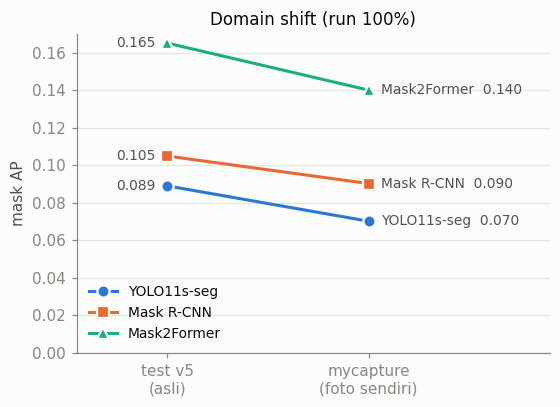

In [10]:
ds = allm[allm.split.isin(["test_v5", "mycapture"])].pivot_table(index=["model", "run"], columns="split", values="mask_AP")
ds["selisih"] = ds["mycapture"] - ds["test_v5"]
ds["perubahan %"] = 100 * ds["selisih"] / ds["test_v5"]
display(ds.round(3))
fig = AN.plot_domain_shift(allm, "100pct")
fig.savefig(f"{OUT}/grafik_domain_shift.png", dpi=150, bbox_inches="tight")

### 5.4 AP per kelas di mycapture (run 100%)

Hanya kelas yang muncul di mycapture. Kolom `train v5` = jumlah contoh kelas itu di data latih.

In [11]:
pc = {}
for key in MODELS:
    _, per_cls = coco_evaluate(GT["mycapture"], preds[(key, "100pct", "mycapture")], MAX_DET)
    pc[AN.LABELS[key]] = per_cls
pc = pd.DataFrame(pc).reindex(cls_tab.index).fillna(0.0)
pc_tab = pd.concat([cls_tab[["mycapture", "train v5"]], pc], axis=1)
pc_tab["rata-rata 3 model"] = pc.mean(axis=1)
pc_tab.to_csv(f"{OUT}/per_class_AP_mycapture_100pct.csv")
pc_tab.sort_values("rata-rata 3 model", ascending=False).round(3)

,mycapture,train v5,YOLO11s-seg,Mask R-CNN,Mask2Former,rata-rata 3 model
ceiling-merged,9,77,0.557,0.735,0.669,0.654
laptop,5,8,0.376,0.346,0.700,0.474
wall-other-merged,61,756,0.402,0.399,0.443,0.415
person,12,192,0.383,0.313,0.502,0.399
floor-wood,10,99,0.172,0.469,0.441,0.361
pillow,11,39,0.353,0.260,0.442,0.351
bed,6,26,0.204,0.223,0.336,0.254
sink,4,8,0.000,0.379,0.355,0.245
floor-other-merged,28,261,0.161,0.245,0.141,0.182
door-stuff,10,64,0.146,0.218,0.102,0.155


### 5.5 AP per kondisi foto (run 100%)

AP dihitung ulang hanya pada foto dengan label kondisi tertentu. Jumlah fotonya kecil, jadi angka ini indikatif.

In [12]:
groups = {"semua": [i for i in cond]}
groups.update({c: [i for i, s in cond.items() if c in s] for c in labels})
rows = []
for name, ids in groups.items():
    r = {"kondisi": name, "foto": len(ids)}
    for key in MODELS:
        s, _ = coco_evaluate(GT["mycapture"], preds[(key, "100pct", "mycapture")], MAX_DET, img_ids=ids)
        r[AN.LABELS[key]] = s["AP"]
    rows.append(r)
cond_tab = pd.DataFrame(rows).set_index("kondisi")
cond_tab.round(3)

,foto,YOLO11s-seg,Mask R-CNN,Mask2Former
kondisi,,,,
semua,59,0.070,0.090,0.140
backlight,7,0.098,0.130,0.191
normal,34,0.100,0.145,0.177
penuh,15,0.092,0.092,0.162
redup,1,0.167,0.150,0.324
saling menutupi,14,0.133,0.130,0.219
sudut ekstrem,1,0.025,0.128,0.301


### 5.6 Statistik per foto (run 100%)

Untuk memilih foto analisis kegagalan: per foto dihitung objek yang terdeteksi benar (IoU ≥ 0,5 dan kelas sama,
skor ≥ 0,3), objek yang luput, prediksi yang menutupi objek tapi kelasnya salah, dan prediksi di tempat yang tidak ada
objeknya.

In [13]:
per_img = {key: AN.image_stats(gt["mycapture"], preds[(key, "100pct", "mycapture")]) for key in MODELS}
pi = pd.concat({AN.LABELS[k]: v.set_index("foto")[["n_gt", "recall", "salah_kelas", "prediksi_salah"]]
                for k, v in per_img.items()}, axis=1)
pi[("rata-rata", "recall")] = pi.xs("recall", axis=1, level=1).mean(axis=1)
pi.sort_values(("rata-rata", "recall")).head(15).round(2)

YOLO11s-seg                                   Mask R-CNN         \
            n_gt recall salah_kelas prediksi_salah       n_gt recall   
foto                                                                   
28            36   0.03           0              4         36   0.00   
55            19   0.05           1              0         19   0.11   
41            28   0.04           1              8         28   0.07   
29            15   0.07           3              4         15   0.07   
40            30   0.03           0              7         30   0.10   
26            39   0.05           0              4         39   0.05   
42             6   0.00           2              2          6   0.17   
50            12   0.00           1              3         12   0.08   
57            10   0.10           1             10         10   0.20   
59            15   0.13           0              6         15   0.20   
19            17   0.06           2              6         17   0.12   
1             12   0.00           0              3         12   0.25   
56            16   0.06           0              7         16   0.06   
36            11   0.18           0              4         11   0.09   
45            10   0.10           3              7         10   0.20   

                                Mask2Former                                    \
     salah_kelas prediksi_salah        n_gt recall salah_kelas prediksi_salah   
foto                                                                            
28             4             15          36   0.17           3             36   
55             1             13          19   0.05           2             20   
41             6             11          28   0.14           2             19   
29             6              2          15   0.13           3             11   
40             5             21          30   0.13           5             31   
26             2             16          39   0.18           3             33   
42             5              8           6   0.17           1             16   
50             4              7          12   0.25           4             16   
57             2             19          10   0.10           1             21   
59             2             22          15   0.07           1             21   
19             6              8          17   0.24           6             17   
1              4              8          12   0.17           1              4   
56             2             18          16   0.31           2             17   
36             5             11          11   0.18           2              5   
45             2              5          10   0.20           2              6   

     rata-rata  
        recall  
foto            
28        0.06  
55        0.07  
41        0.08  
29        0.09  
40        0.09  
26        0.09  
42        0.11  
50        0.11  
57        0.13  
59        0.13  
19        0.14  
1         0.14  
56        0.15  
36        0.15  
45        0.17

## 6. Pembahasan dan uji hipotesis

### 6.1 Kelas yang dihipotesiskan bagus

In [14]:
hyp = pc_tab.loc[["wall-other-merged", "person", "chair"], ["mycapture", "train v5"] + [AN.LABELS[k] for k in MODELS]].copy()
rank = pc_tab["rata-rata 3 model"].rank(ascending=False, method="min").astype(int)
hyp[f"peringkat (dari {len(pc_tab)} kelas)"] = rank[hyp.index]
hyp.loc["rata-rata semua kelas"] = [np.nan, np.nan] + [pc[AN.LABELS[k]].mean() for k in MODELS] + [np.nan]
display(hyp.round(3))

chair_frac = pd.DataFrame({AN.LABELS[k]: [coco_evaluate(GT["mycapture"], preds[(k, t, "mycapture")], MAX_DET)[1].get("chair", 0)
                                          for t in FRACS] for k in MODELS}, index=[f"AP chair, data {AN.FRAC_LABEL[t]}" for t in FRACS])
chair_frac.round(3)

,mycapture,train v5,YOLO11s-seg,Mask R-CNN,Mask2Former,peringkat (dari 53 kelas)
wall-other-merged,61.0,756.0,0.402,0.399,0.443,3.0
person,12.0,192.0,0.383,0.313,0.502,4.0
chair,104.0,217.0,0.013,0.033,0.048,30.0
rata-rata semua kelas,NaN,NaN,0.070,0.090,0.140,NaN


,YOLO11s-seg,Mask R-CNN,Mask2Former
"AP chair, data 25%",0.083,0.011,0.026
"AP chair, data 50%",0.006,0.024,0.059
"AP chair, data 100%",0.013,0.033,0.048


### 6.2 Ringkasan uji hipotesis

| # | Hipotesis | Hasil | Status |
|---|---|---|---|
| 1.1 | Semua model berperforma buruk | Mask AP mycapture 0,07–0,14 dan test v5 0,09–0,17 (run 100%). Bobot yang sama mencapai sekitar 0,38–0,45 di COCO. | **Terdukung** |
| 1.2 | Ketimpangan data membuat AP test v5 jauh di bawah AP valid | Valid vs test v5 (100%): YOLO 0,212 vs 0,089; Mask R-CNN 0,186 vs 0,105; Mask2Former 0,288 vs 0,165 | **Terdukung** |
| 1.3 | AP mycapture < AP test v5 untuk semua model | Turun di **9 dari 9 run**, sebesar 14–32% | **Terdukung** |
| 2.1 | Mask2Former terbaik | Terbaik di semua fraksi: 0,122 / 0,135 / 0,140 | **Terdukung** |
| 2.2 | Mask R-CNN terburuk | Benar di 25% (0,044) dan 50% (0,061 vs YOLO 0,065), **salah di 100%** (Mask R-CNN 0,090 > YOLO 0,070) | **Sebagian** |
| 2.3 | `wall-other-merged` bagus | AP rata-rata 0,415, peringkat 3 dari 53 kelas | **Terdukung** |
| 2.3 | `person` bagus | AP rata-rata 0,399, peringkat 4 dari 53 kelas | **Terdukung** |
| 2.3 | `chair` bagus | AP hanya 0,013–0,048, peringkat 30 dari 53, padahal ada 217 contoh train | **Tidak terdukung** |

### 6.3 Mengapa sebagian hipotesis keliru

**Kursi ternyata salah satu kelas terburuk.** Alasan "contoh train banyak" ternyata tidak cukup. Ada tiga penyebab:
1. **Kursi di mycapture berbeda jenis dengan kursi di v5.** Kursi v5 kebanyakan kursi rumah tunggal, sedangkan
   sebagian besar kursi di mycapture (104 objek) adalah kursi kuliah, kursi banket ballroom, dan stool besi yang
   tersusun rapat dalam barisan. Mask R-CNN dan Mask2Former menganggap barisan kursi itu sebagai **tangga (`stairs`)**,
   kelas dengan 175 contoh train walaupun mycapture tidak punya tangga sama sekali (lihat Kasus 1).
2. **YOLO "melupakan" kursi COCO.** AP chair YOLO justru turun dari 0,083 (data 25%) ke 0,013 (data 100%).
   Mekanismenya sama dengan Kasus 2.
3. **Alasan dari sisi jumlah di test set kurang tepat.** Sedikitnya objek di test set tidak membuat AP lebih tinggi;
   yang menentukan adalah kemiripan tampilan objek test dengan objek train. Kursi di mycapture juga banyak yang kecil
   dan saling menutupi, dan AP objek kecil semua model hanya 0,01–0,03.

**Mask R-CNN bukan yang terburuk di 100%.** Urutan YOLO dan Mask R-CNN tertukar karena cara transfer learning-nya berbeda:
- **YOLO** memakai ulang bobot kepala klasifikasi COCO untuk kelas yang namanya sama. Di data 25%, YOLO mendapat
  "bonus" dari pengetahuan COCO (best epoch 3). Semakin lama dilatih di v5, bonus itu hilang:
  0,107 → 0,065 → 0,070 di mycapture.
- **Mask R-CNN** memulai kepala klasifikasinya dari nol, jadi butuh data. AP-nya naik terus seiring data:
  0,044 → 0,061 → 0,090. Dengan data cukup, desain two-stage (RoIAlign per objek) tetap bersaing.
- Jadi perbedaan "YOLO fokus kecepatan" tidak menjelaskan semuanya. Yang menentukan urutan di sini adalah
  **interaksi antara jumlah data dan cara kepala klasifikasi diinisialisasi**.

**Mengapa Mask2Former unggul.** Setiap query memprediksi satu mask utuh dengan loss tingkat mask dan dicocokkan satu-satu
(Hungarian matching), tanpa box, tanpa RoI, dan tanpa NMS. Keunggulannya paling terlihat pada objek besar
(AP large 0,27 vs 0,12–0,19) dan kelas berbentuk area seperti `window-other` (0,256 vs 0,02–0,03).

### 6.4 Variabel NRP: pengaruh jumlah data latih

- **Mask2Former** naik tapi mulai mendatar: 0,122 → 0,135 → 0,140 di mycapture, dan 0,146 → 0,164 → 0,165 di test v5.
  Run 100% hanya sempat 28 epoch karena batas 40 menit, sehingga jumlah iterasinya hampir sama dengan run 50%.
  Pada anggaran GPU yang tetap, menambah data dari 50% ke 100% hampir tidak menambah AP.
- **Mask R-CNN** paling "lapar data": AP mycapture naik dua kali lipat dari 25% ke 100%.
- **YOLO** justru turun saat data ditambah, baik di test v5 maupun mycapture, karena *catastrophic forgetting*
  (Kasus 2), padahal di valid naik (0,129 → 0,212). Ini contoh bahwa **valid saja bisa menyesatkan**: checkpoint
  terbaik di valid belum tentu yang paling tahan domain shift.

### 6.5 Domain shift

Semua run turun dari test v5 ke mycapture, dengan penurunan terkecil di Mask R-CNN 100% (−14%) dan Mask2Former (−15 s.d. −18%).
Penurunan ini **lebih kecil daripada selisih valid → test v5**. Ini cocok dengan temuan bahwa test v5 sendiri
sudah berbeda distribusinya dari train/valid, misalnya label kardus `box` vs `cardboard`.

### 6.6 Kondisi foto

AP per kondisi **tidak** menunjukkan pola "foto sulit = AP rendah" yang konsisten. Selisihnya kecil dan arahnya
berbeda antar model:
- Pada YOLO dan Mask2Former, foto `saling menutupi` justru lebih tinggi daripada foto `normal`.
- Pada Mask R-CNN, foto `backlight` dan `saling menutupi` sedikit lebih rendah (0,130 vs 0,145).

Ada tiga sebab:
- Jumlah fotonya kecil: `redup` dan `sudut ekstrem` masing-masing hanya 1 foto.
- AP per kelompok dirata-rata atas kelas yang berbeda-beda.
- Isi foto (kelas apa yang muncul) lebih berpengaruh daripada pencahayaan. Contohnya, foto ballroom dan kelas yang
  "penuh" berisi kursi, yang memang gagal karena alasan di 6.3.

Kesimpulannya, kondisi foto bukan faktor dominan pada data ini (lihat juga Kasus 4).

## 7. Analisis kegagalan berbasis bukti

**Cara memilih foto.** Kandidat diambil dari tabel 5.6 (foto dengan recall terendah), lalu dipilih 5 foto yang mewakili
jenis kegagalan berbeda dan bisa dikaitkan dengan mekanisme model:

| Kasus | Foto | Jenis kegagalan | Mekanisme yang diuji | Eksperimen |
|---|---|---|---|---|
| 1 | #55 ballroom | tidak terdeteksi / salah kelas (kursi → tangga) | klasifikasi region & prior kelas | crop + zoom |
| 2 | #51 lab | kelas tanpa contoh train tidak terdeteksi | inisialisasi kepala klasifikasi YOLO dari COCO | bandingkan data 25/50/100% |
| 3 | #28 dapur | objek kecil rapat, salah kelas (piring → panci) | resolusi fitur pada objek kecil | crop + zoom |
| 4 | #41 ruang tamu | backlight, banyak objek luput | sensitivitas fitur terhadap pencahayaan | koreksi gamma |
| 5 | #49 kafe | mask stool berkaki tipis buruk | resolusi mask: grid 28×28 Mask R-CNN & prototype YOLO | batas atas 28×28, ubah `imgsz` YOLO |

Pada gambar di bawah, panel kiri adalah anotasi, dan panel lain adalah prediksi setiap model (run 100%, skor ≥ 0,3).
Tanda `*` pada label anotasi berarti area crowd. "Tidak terdeteksi" berarti tidak ada prediksi (skor ≥ 0,1) yang
menutupi objek dengan IoU ≥ 0,3.

Sel berikut menyiapkan versi foto untuk eksperimen (zoom, koreksi gamma) dan menjalankan ketiga model sekali saja.

In [15]:
cid = {n: i + 1 for i, n in enumerate(classes)}
G = gt["mycapture"]
inv = {AN.photo_number(im["orig_file_name"]): im["id"] for im in G["images"]}
P100 = {k: preds[(k, "100pct", "mycapture")] for k in MODELS}
EXP = f"{OUT}/eksperimen"
backlight_ids = [i for i, s in cond.items() if "backlight" in s]

# Versi foto untuk eksperimen (anotasi ikut disesuaikan)
V = {
    "zoom55": AN.crop_zoom(G, inv[55], AN.union_box(G, inv[55], {cid["chair"]}), EXP, f"{EXP}/zoom55.json"),
    "zoom28": AN.crop_zoom(G, inv[28], AN.union_box(G, inv[28], {cid[c] for c in ["plate", "spoon", "cup", "fork"]}),
                           EXP, f"{EXP}/zoom28.json"),
    "backlight_asli": AN.make_variant(G, backlight_ids, lambda im: im, f"{EXP}/backlight_asli", f"{EXP}/backlight_asli.json"),
    "backlight_gamma": AN.make_variant(G, backlight_ids, lambda im: AN.gamma_correct(im, 0.5),
                                       f"{EXP}/backlight_gamma", f"{EXP}/backlight_gamma.json"),
}
XP = {}
for k in MODELS:
    m = MD.load_model(k, f"{k}/100pct", classes, score_thresh=SCORE_THRESH, max_det=MAX_DET)
    for name, c in V.items():
        XP[(k, name)] = m.predict_coco(c)
    if k == "yolo11s":                      # eksperimen resolusi input/prototype YOLO
        for sz in (960, 1280):
            XP[(k, f"imgsz{sz}")] = m.predict_coco(G, imgsz=sz)
    del m
    MD.free_gpu()


def at_table(items):
    """items: list (label, Counter kelas di lokasi objek) -> tabel."""
    return pd.DataFrame({lab: c for lab, c in items}).T.fillna(0).astype(int)

print("eksperimen selesai:", len(XP), "set prediksi")

eksperimen selesai: 14 set prediksi


### 7.1 Kasus 1 – Foto #55 (ballroom): barisan kursi dikira tangga

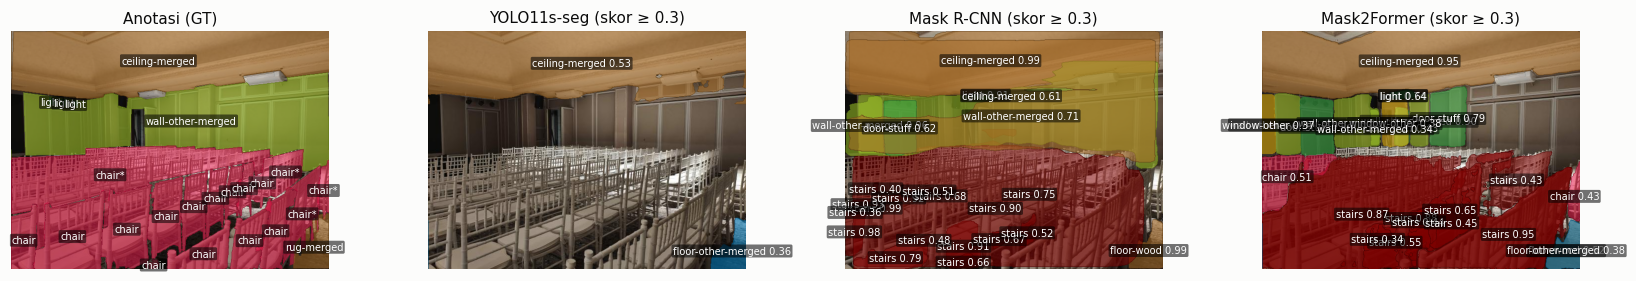

,(tidak terdeteksi),stairs
YOLO11s-seg,13,0
Mask R-CNN,10,3
Mask2Former,9,4


,"prediksi 'stairs' (skor ≥ 0,3)",jumlah foto,objek stairs di mycapture,stairs di train v5
YOLO11s-seg,11,8,0,175
Mask R-CNN,88,20,0,175
Mask2Former,46,8,0,175


In [16]:
AN.show_case(inv[55], G, P100, classes).savefig(f"{EXP}/kasus1_55.png", dpi=130, bbox_inches="tight")
plt.show()
display(at_table([(AN.LABELS[k], AN.predicted_at(G, P100[k], inv[55], cid["chair"], classes)) for k in MODELS]))
pd.DataFrame({AN.LABELS[k]: {"prediksi 'stairs' (skor ≥ 0,3)": sum(1 for d in P100[k] if d["category_id"] == cid["stairs"] and d["score"] >= 0.3),
                             "jumlah foto": len({d["image_id"] for d in P100[k] if d["category_id"] == cid["stairs"] and d["score"] >= 0.3})}
              for k in MODELS}).T.assign(**{"objek stairs di mycapture": 0, "stairs di train v5": int(stats.loc["stairs", "instances_train"])})

**Eksperimen:** kalau kegagalan ini karena kursi terlalu kecil di input 640, memotong area kursi lalu memperbesarnya
(zoom) seharusnya membuat kursi terdeteksi sebagai `chair`.

,(tidak terdeteksi),stairs
YOLO11s-seg – foto penuh,13,0
Mask R-CNN – foto penuh,10,3
Mask2Former – foto penuh,9,4
YOLO11s-seg – zoom,13,0
Mask R-CNN – zoom,12,1
Mask2Former – zoom,8,5


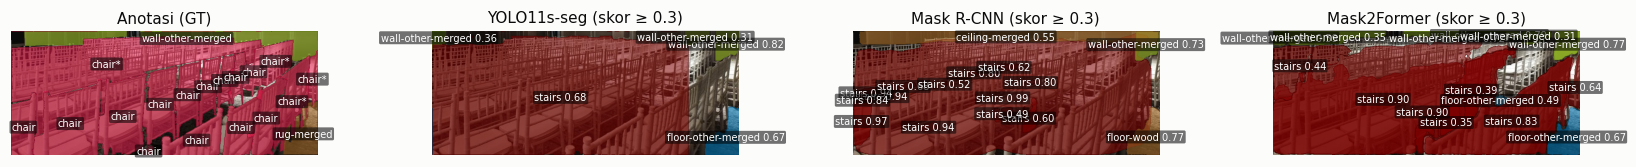

In [17]:
z = V["zoom55"]; zid = z["images"][0]["id"]
display(at_table([(f"{AN.LABELS[k]} – foto penuh", AN.predicted_at(G, P100[k], inv[55], cid["chair"], classes)) for k in MODELS] +
                 [(f"{AN.LABELS[k]} – zoom", AN.predicted_at(z, XP[(k, "zoom55")], zid, cid["chair"], classes)) for k in MODELS]))
AN.show_case(zid, z, {k: XP[(k, "zoom55")] for k in MODELS}, classes).savefig(f"{EXP}/kasus1_55_zoom.png", dpi=130, bbox_inches="tight")

**Pengamatan.** Foto ini berisi 13 kursi banket yang dianotasi satu per satu, ditambah area `chair-crowd` di belakang.
Tidak ada satu pun kursi yang tersegmentasi sebagai `chair` oleh ketiga model.
- YOLO tidak mendeteksi apa pun di area kursi.
- Mask R-CNN dan Mask2Former menutupi **barisan** kursi dengan mask besar berlabel **`stairs`**.
- Di seluruh mycapture, yang sama sekali tidak memuat tangga, Mask R-CNN membuat 88 prediksi `stairs` (skor ≥ 0,3) di
  20 foto, dan Mask2Former 46 di 8 foto.

**Penyebab (mekanisme).**
- Kedua model memberi kelas pada sebuah region: Mask R-CNN lewat fitur RoI dari proposal, Mask2Former lewat satu query
  yang mask-nya menutupi satu area.
- Barisan sandaran kursi putih yang berulang menghasilkan pola garis horizontal sejajar, mirip anak tangga.
- Kelas `stairs` punya 175 contoh train (69 gambar), sedangkan kursi banket tidak ada di v5. Classifier memilih kelas
  yang pola visualnya paling mirip di data latih.
- YOLO memprediksi per lokasi grid. Skor kursinya di sini tidak cukup tinggi untuk lolos, dan kelas `chair` di YOLO juga
  terkena *forgetting* (AP chair 0,083 di data 25% → 0,013 di 100%).

**Eksperimen: crop + zoom area kursi.** Kalau penyebabnya kursi terlalu kecil di input 640, memperbesar area kursi
seharusnya membuat kursi terdeteksi.
- **Hasil:** setelah zoom, tetap **tidak ada kursi yang terdeteksi sebagai `chair`**. Mask2Former malah menambah
  prediksi `stairs`.
- **Kesimpulan:** ukuran bukan penyebab utama. Kegagalannya ada pada **klasifikasi**: tampilan kursi banket berderet tidak
  ada di data latih, dan region seperti itu didorong ke kelas `stairs` yang sering muncul di train.

### 7.2 Kasus 2 – Foto #51 (lab komputer): keyboard, mouse, dan monitor

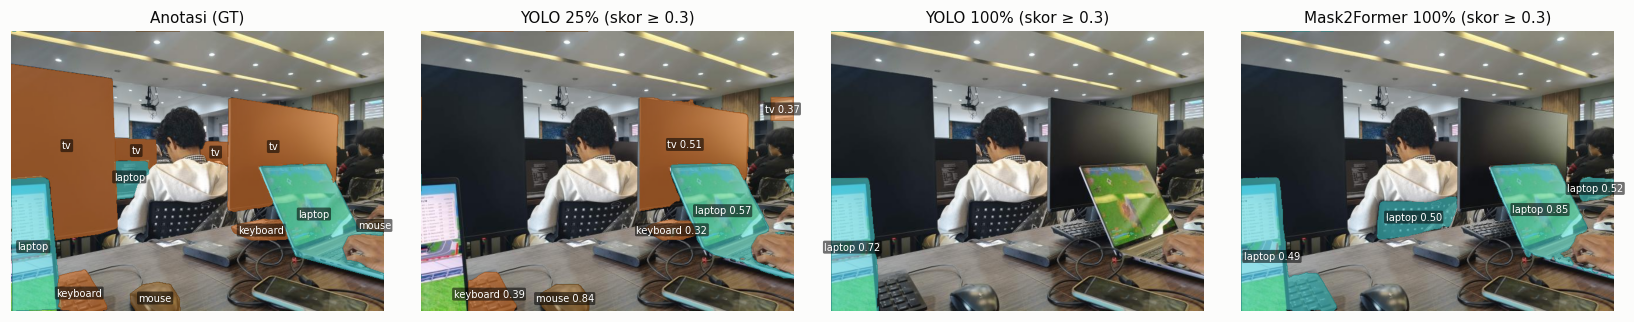

Jumlah objek yang tersegmentasi benar (IoU ≥ 0,5, kelas sama, skor ≥ 0,3); angka dalam kurung = jumlah objek di foto.

tv (4)  keyboard (2)  mouse (2)  laptop (3)
model       data                                             
YOLO11s-seg 25%        1             2          1           1
            50%        0             0          0           1
            100%       0             0          0           1
Mask R-CNN  25%        0             0          0           0
            50%        0             0          0           1
            100%       0             0          0           1
Mask2Former 25%        0             0          0           0
            50%        0             0          0           2
            100%       0             0          0           2

,train v5,test v5
class,,
tv,2,35
keyboard,0,7
mouse,0,8
laptop,8,27


In [18]:
lab51 = {cid[c] for c in ["tv", "keyboard", "mouse", "laptop"]}
cases51 = {"YOLO 25%": preds[("yolo11s", "025pct", "mycapture")], "YOLO 100%": P100["yolo11s"], "Mask2Former 100%": P100["mask2former"]}
AN.show_case(inv[51], G, cases51, classes, only=lab51).savefig(f"{EXP}/kasus2_51.png", dpi=130, bbox_inches="tight")
plt.show()
rows = []
for k in MODELS:
    for t in FRACS:
        r = {"model": AN.LABELS[k], "data": AN.FRAC_LABEL[t]}
        for c in ["tv", "keyboard", "mouse", "laptop"]:
            iou = AN.matched_iou(G, preds[(k, t, "mycapture")], inv[51], cid[c])
            r[f"{c} ({len(iou)})"] = int((iou >= 0.5).sum())
        rows.append(r)
display(Markdown("Jumlah objek yang tersegmentasi benar (IoU ≥ 0,5, kelas sama, skor ≥ 0,3); angka dalam kurung = jumlah objek di foto."))
display(pd.DataFrame(rows).set_index(["model", "data"]))
stats.loc[["tv", "keyboard", "mouse", "laptop"], ["instances_train", "instances_test"]].rename(
    columns={"instances_train": "train v5", "instances_test": "test v5"})

**Pengamatan.**
- Foto lab ini memuat 4 monitor (`tv`), 2 `keyboard`, 2 `mouse`, dan 3 `laptop`. Di train v5, `keyboard` dan `mouse`
  tidak punya contoh sama sekali, dan `tv` hanya 2.
- Satu-satunya model yang bisa menyegmentasi keyboard, mouse, dan monitor adalah **YOLO dengan data 25%**:
  2/2 keyboard, 1/2 mouse, dan 1/4 monitor.
- YOLO 50% dan 100%, serta semua run Mask R-CNN dan Mask2Former, tidak mendapat satu pun. Hanya `laptop` (8 contoh train)
  yang tetap terdeteksi.

**Penyebab (mekanisme).**
- Saat fine-tuning, Ultralytics menyalin bobot kepala klasifikasi COCO untuk kelas yang namanya sama, termasuk
  `keyboard`, `mouse`, dan `tv`. Jadi YOLO mulai dengan kemampuan mengenali benda-benda ini dari COCO.
- Run 25% berhenti di best epoch 3, sehingga kemampuan itu masih utuh.
- Run 50% dan 100% dilatih lebih lama (best epoch 42 dan 84) di v5, yang tidak punya contoh keyboard atau mouse.
  Akibatnya kelas itu hanya muncul sebagai "latar" dan skornya terus ditekan. Inilah *catastrophic forgetting*.
- Mask R-CNN dan Mask2Former memulai kepala klasifikasinya dari nol, sehingga **tidak pernah** bisa mengenali kelas tanpa contoh train.

**Eksperimen: bandingkan run 25/50/100%.** Ketiga run memakai arsitektur dan bobot awal yang sama. Yang berbeda adalah
jumlah data dan lama training efektifnya.
- **Hasil:** kemampuan hilang begitu training lebih panjang (25% → 50%). Pola yang sama terlihat pada AP chair YOLO
  (0,083 → 0,006 → 0,013) dan pada test v5 (`keyboard`, `mouse`, `scissors`; lihat Bagian 2.6).
- **Kesimpulan:** kemampuan zero-shot dari bobot pretrained rapuh. Cara mempertahankannya antara lain: membekukan
  sebagian kepala klasifikasi, mencampur sedikit data COCO saat fine-tuning, atau menambah contoh kelas tersebut ke data latih.

### 7.3 Kasus 3 – Foto #28 (dapur, rak piring): piring dikira panci

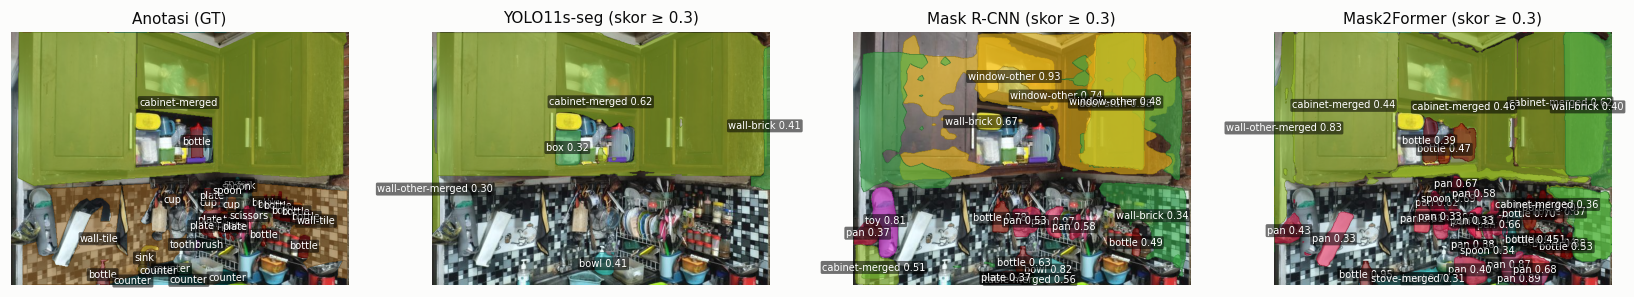

,(tidak terdeteksi),pan,plate,chair
YOLO11s-seg – foto penuh,7,1,0,0
Mask R-CNN – foto penuh,6,2,0,0
Mask2Former – foto penuh,5,3,0,0
YOLO11s-seg – zoom,8,0,0,0
Mask R-CNN – zoom,3,1,3,1
Mask2Former – zoom,1,1,6,0


,foto penuh,zoom area rak
YOLO11s-seg,0.03,0.00
Mask R-CNN,0.00,0.10
Mask2Former,0.17,0.15


,train v5,test v5
class,,
plate,86,104
pan,225,34
bowl,65,76
cup,25,131
spoon,35,36


In [19]:
AN.show_case(inv[28], G, P100, classes).savefig(f"{EXP}/kasus3_28.png", dpi=130, bbox_inches="tight")
plt.show()
z = V["zoom28"]; zid = z["images"][0]["id"]
display(at_table([(f"{AN.LABELS[k]} – foto penuh", AN.predicted_at(G, P100[k], inv[28], cid["plate"], classes)) for k in MODELS] +
                 [(f"{AN.LABELS[k]} – zoom", AN.predicted_at(z, XP[(k, "zoom28")], zid, cid["plate"], classes)) for k in MODELS]))
display(pd.DataFrame({"foto penuh": {AN.LABELS[k]: AN.image_stats(G, P100[k]).set_index("foto").loc[28, "recall"] for k in MODELS},
                      "zoom area rak": {AN.LABELS[k]: AN.image_stats(z, XP[(k, "zoom28")]).iloc[0]["recall"] for k in MODELS}}).round(2))
stats.loc[["plate", "pan", "bowl", "cup", "spoon"], ["instances_train", "instances_test"]].rename(
    columns={"instances_train": "train v5", "instances_test": "test v5"})

**Pengamatan.**
- Foto rak piring ini punya recall terendah di seluruh mycapture. Isinya 36 objek kecil yang saling menempel:
  8 piring berdiri di rak, gelas, sendok, garpu, gunting, sikat gigi, dan botol.
- Di foto penuh, tidak ada piring yang dikenali sebagai `plate`. Sebagian besar tidak terdeteksi, dan sisanya dilabeli
  **`pan`** (panci/wajan).

**Penyebab (mekanisme).**
- Di input 640×480, sebuah piring yang berdiri di rak hanya selebar beberapa piksel.
- Ketiga model membentuk mask dari peta fitur beresolusi rendah: prototype YOLO dan pixel decoder Mask2Former di 1/4
  input, dan RoI Mask R-CNN dari level FPN dengan stride 4–32. Detail tepi piring yang membedakannya dari panci
  hampir hilang di resolusi itu.
- Ketika fiturnya ambigu, classifier condong ke kelas yang lebih sering dilihat: `pan` punya 225 contoh train,
  `plate` 86.

**Eksperimen: crop + zoom area rak (±3,7×).**
- **Hasil:** setelah area rak diperbesar, Mask2Former melabeli 6 dari 8 piring sebagai `plate`, dan Mask R-CNN 3.
  Sebelumnya keduanya 0.
- Ini berbeda dengan Kasus 1: di sini **resolusi memang penyebab utama** bagi Mask R-CNN dan Mask2Former.
- YOLO tetap tidak mendeteksi apa pun, sehingga pada YOLO ada faktor lain, yaitu kepala klasifikasi yang terkena
  *forgetting* dan kapasitas model kecil.
- **Kesimpulan:** untuk objek kecil yang rapat, input 640 terlalu kasar. Tiling atau inferensi resolusi lebih tinggi
  (dengan model yang dilatih pada skala tersebut) adalah perbaikan yang masuk akal.

### 7.4 Kasus 4 – Foto #41 (ruang tamu, backlight)

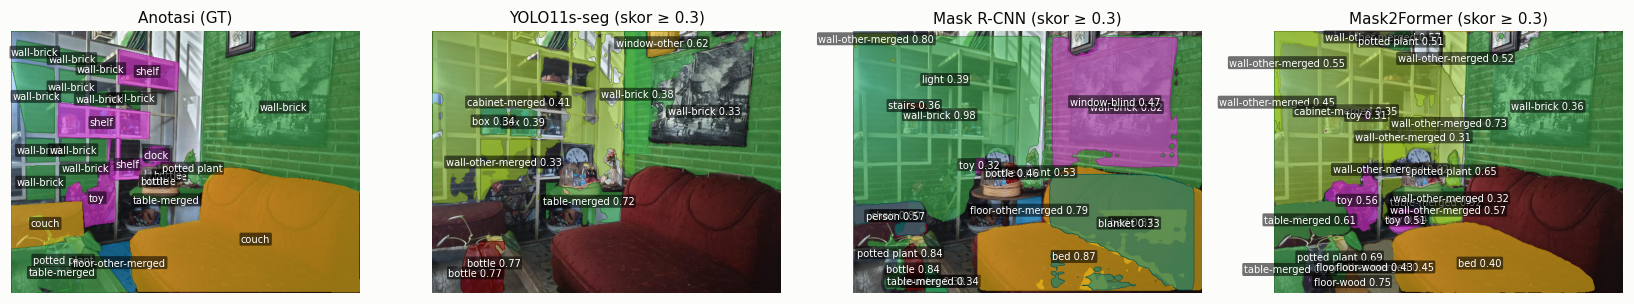

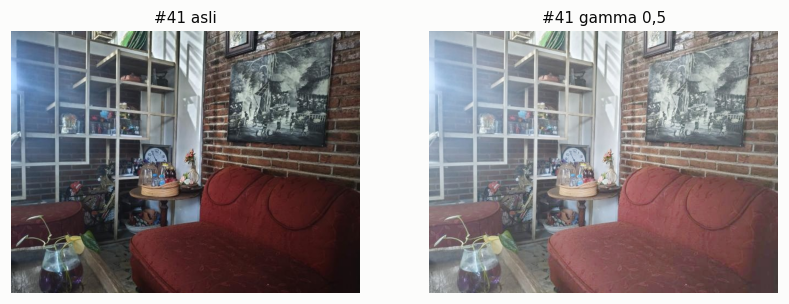

Mask AP pada **7 foto backlight** sebelum dan sesudah koreksi gamma.

,AP asli,"AP gamma 0,5",selisih
YOLO11s-seg,0.097,0.126,0.030
Mask R-CNN,0.129,0.126,-0.003
Mask2Former,0.235,0.157,-0.078


In [20]:
AN.show_case(inv[41], G, P100, classes).savefig(f"{EXP}/kasus4_41.png", dpi=130, bbox_inches="tight")
plt.show()
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for a, (name, c) in zip(ax, [("asli", V["backlight_asli"]), ("gamma 0,5", V["backlight_gamma"])]):
    im = next(i for i in c["images"] if i["id"] == inv[41])
    a.imshow(plt.imread(im["path"])); a.set_title(f"#41 {name}", fontsize=10); a.set_axis_off()
plt.show()
rows = {}
for k in MODELS:
    a, _ = coco_evaluate(f"{EXP}/backlight_asli.json", XP[(k, "backlight_asli")], MAX_DET)
    b, _ = coco_evaluate(f"{EXP}/backlight_gamma.json", XP[(k, "backlight_gamma")], MAX_DET)
    rows[AN.LABELS[k]] = {"AP asli": a["AP"], "AP gamma 0,5": b["AP"], "selisih": b["AP"] - a["AP"]}
display(Markdown(f"Mask AP pada **{len(backlight_ids)} foto backlight** sebelum dan sesudah koreksi gamma."))
pd.DataFrame(rows).T.round(3)

**Pengamatan.**
- Ruang tamu ini difoto melawan cahaya jendela, sehingga bagian dalam ruangan (sofa, rak, mainan, jam) gelap.
- Recall di foto ini rendah untuk semua model: YOLO 0,04, Mask R-CNN 0,07, Mask2Former 0,14, dari 28 objek.

**Penyebab yang diduga (mekanisme).** Data v5 kebanyakan foto dengan pencahayaan rata. Pada area yang kurang terang,
kontras tepi dan warna mengecil, sehingga aktivasi fitur awal CNN (yang dinormalisasi dengan statistik BatchNorm dari
data latih) melemah. Kalau dugaan ini benar, mencerahkan bagian gelap seharusnya menolong.

**Eksperimen: koreksi gamma 0,5 pada 7 foto backlight** (bagian gelap dicerahkan, anotasi tetap).
- **YOLO:** AP naik dari 0,097 ke 0,126 (**+0,030**).
- **Mask R-CNN:** praktis tidak berubah (−0,003).
- **Mask2Former:** AP **turun** dari 0,235 ke 0,157 (−0,078).

**Kesimpulan.**
- Dugaan "kurang terang" hanya berlaku untuk YOLO, model terkecil dengan backbone CNN.
- Mask2Former (backbone Swin dengan LayerNorm dan attention) sudah cukup tahan terhadap foto gelap. Koreksi gamma justru
  menggeser distribusi warna dan menguatkan noise, sehingga hasilnya memburuk.
- Rendahnya recall #41 lebih banyak disebabkan isi fotonya: banyak benda kecil, `toy`, `clock`, `shelf` yang contoh
  train-nya sedikit atau berbeda bentuk. Ini konsisten dengan tabel 5.5, di mana AP foto backlight tidak jauh berbeda
  dari foto normal.
- Preprocessing pencahayaan **tidak bisa diterapkan sama rata** ke semua model. Jumlah fotonya juga hanya 7, jadi efek ini indikatif.

### 7.5 Kasus 5 – Foto #49 (kafe, stool besi berkaki tipis): apakah resolusi mask yang jadi masalah?

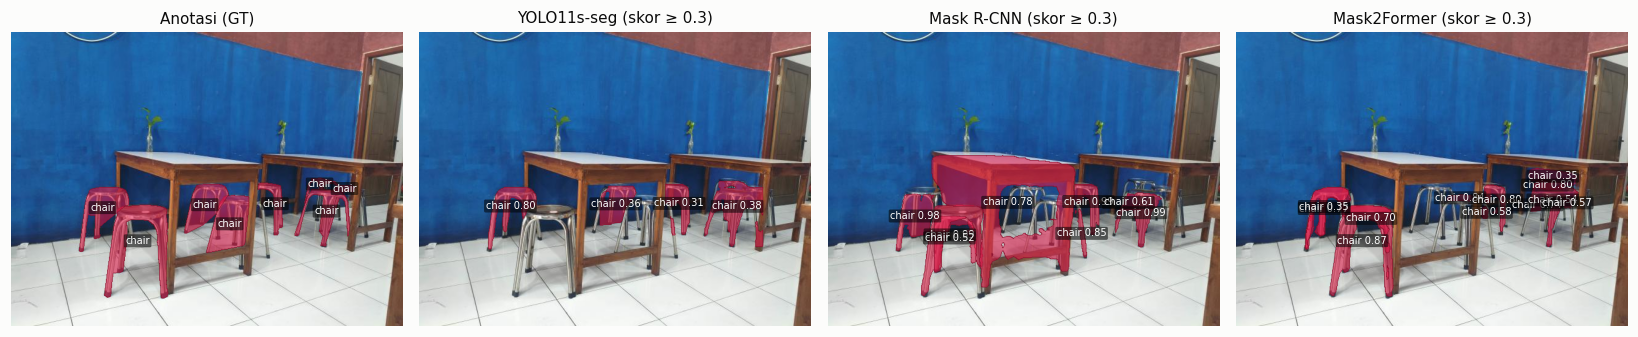

**(a) Batas atas mask 28×28** untuk 8 stool di #49, dibanding IoU yang benar-benar dicapai model:

,nilai
batas atas grid 28×28 (rata-rata IoU),0.973
IoU tercapai YOLO11s-seg,0.312
IoU tercapai Mask R-CNN,0.324
IoU tercapai Mask2Former,0.354


Batas atas 28×28 untuk **semua** objek mycapture: rata-rata IoU 0.985 (kelas terendah: shelf 0.924).

**(b) YOLO dengan input lebih besar** (prototype mask ikut lebih tajam, model tetap dilatih di 640):

,resolusi prototype,mask AP mycapture,AP chair,IoU stool #49
imgsz YOLO,,,,
640,160×160,0.070,0.013,0.312
960,240×240,0.062,0.009,0.292
1280,320×320,0.046,0.001,0.124


In [21]:
AN.show_case(inv[49], G, P100, classes, only={cid["chair"]}).savefig(f"{EXP}/kasus5_49.png", dpi=130, bbox_inches="tight")
plt.show()
ub = AN.roi_mask_upper_bound(G, 28, classes)
ub49 = ub[(ub.foto == 49) & (ub.kelas == "chair")]
r = {"batas atas grid 28×28 (rata-rata IoU)": ub49.iou_maks.mean()}
r.update({f"IoU tercapai {AN.LABELS[k]}": AN.matched_iou(G, P100[k], inv[49], cid["chair"]).mean() for k in MODELS})
display(Markdown(f"**(a) Batas atas mask 28×28** untuk {len(ub49)} stool di #49, dibanding IoU yang benar-benar dicapai model:"))
display(pd.Series(r).round(3).to_frame("nilai"))
display(Markdown(f"Batas atas 28×28 untuk **semua** objek mycapture: rata-rata IoU {ub.iou_maks.mean():.3f} "
                 f"(kelas terendah: {ub.groupby('kelas').iou_maks.mean().idxmin()} {ub.groupby('kelas').iou_maks.mean().min():.3f})."))
rows = []
for sz in (640, 960, 1280):
    p = P100["yolo11s"] if sz == 640 else XP[("yolo11s", f"imgsz{sz}")]
    s, pcl = coco_evaluate(GT["mycapture"], p, MAX_DET)
    rows.append({"imgsz YOLO": sz, "resolusi prototype": f"{sz // 4}×{sz // 4}", "mask AP mycapture": s["AP"],
                 "AP chair": pcl.get("chair", 0), "IoU stool #49": AN.matched_iou(G, p, inv[49], cid["chair"]).mean()})
display(Markdown("**(b) YOLO dengan input lebih besar** (prototype mask ikut lebih tajam, model tetap dilatih di 640):"))
pd.DataFrame(rows).set_index("imgsz YOLO").round(3)

**Pengamatan.** Kafe ini punya 8 stool besi berkaki tipis. Mask yang dihasilkan ketiga model buruk: IoU rata-rata
dengan anotasi hanya 0,31–0,35. Banyak stool tertangkap sebagai satu gumpalan, atau hanya sebagian dudukannya.

**Hipotesis mekanisme.** Struktur tipis seharusnya paling dirugikan oleh mask beresolusi rendah:
- Mask R-CNN memprediksi mask di **grid 28×28** di dalam box lalu memperbesarnya ke ukuran box.
- YOLO membentuk mask dari **prototype** beresolusi 1/4 input (160×160 untuk input 640).

**Eksperimen (a): batas atas grid 28×28.** Mask anotasi setiap stool dikecilkan ke 28×28 lalu diperbesar kembali,
seperti yang dialami mask head Mask R-CNN. Hasilnya IoU rata-rata **0,973**, sedangkan yang dicapai model hanya ~0,32.
Untuk seluruh objek mycapture, batas atasnya 0,985 (terendah `shelf` 0,924, rak bertiang tipis).

**Eksperimen (b): YOLO dengan input lebih besar.** `imgsz` dinaikkan dari 640 ke 960 dan 1280, sehingga prototype mask
ikut lebih tajam (240×240 dan 320×320). Hasilnya justru memburuk:
- Mask AP mycapture: 0,070 → 0,062 → 0,046.
- IoU stool: 0,312 → 0,292 → 0,124.

**Kesimpulan.**
- Hipotesis resolusi mask **terbantah** untuk data ini. Grid 28×28 dan prototype 160×160 bukan pembatas utama, karena
  di 640×480 stool hanya berukuran puluhan piksel dan anotasi polygon juga tidak menelusuri setiap kaki.
- Kegagalan ada pada **pengenalan dan lokalisasi objek**: box atau query yang tidak pas, dan stool besi yang jarang ada di v5.
- Memperbesar input pada model yang dilatih di 640 membuat ukuran objek tidak sesuai dengan skala yang dipelajari.
- Perbaikan yang lebih tepat adalah menambah contoh kursi/stool dari domain ini ke data latih, bukan menaikkan resolusi mask.

## 8. Kesimpulan dan keterbatasan

**Kesimpulan**
1. **Mask2Former paling baik** di ketiga set evaluasi dan ketiga jumlah data. Pada data 100%, mask AP-nya 0,288 (valid),
   0,165 (test v5), dan 0,140 (mycapture).
2. **Semua model lemah** pada dataset ini, sesuai hipotesis awal. Penyebab utamanya data: train hanya 397 gambar,
   kelas timpang, label tidak konsisten antar-split, dan ada kelas tanpa contoh.
3. **Domain shift nyata.** AP mycapture lebih rendah dari test v5 di semua run (−14% s.d. −32%).
4. **Variabel NRP:** efek menambah data bergantung pada model:
   - Mask R-CNN naik terus.
   - Mask2Former mendatar setelah 50% pada anggaran 40 menit.
   - YOLO justru turun karena *catastrophic forgetting* pada kelas COCO.
5. **Kegagalan di foto sendiri lebih sering berupa salah kelas atau tidak terdeteksi, bukan mask yang kasar.**
   - Kursi berderet dikira tangga.
   - Piring dikira panci.
   - Kelas tanpa contoh hilang.
   - Eksperimen resolusi mask (grid 28×28, prototype YOLO) menunjukkan resolusi mask bukan pembatas utama.

**Keterbatasan**
- mycapture hanya 59 foto, dan banyak kelas hanya punya 1–5 objek, sehingga AP per kelas dan per kondisi kurang stabil.
- Hampir semua anotasi dibuat oleh satu orang, dan polygon tidak menelusuri detail tipis (kaki kursi, rangka rak).
- Batas 40 menit per run membuat jumlah data dan lama training saling terkait. Run 100% Mask2Former hanya 28 epoch.
- Gambar mycapture diperkecil ke 640×480 oleh Roboflow, sehingga detail kecil berkurang (relevan untuk Kasus 3).
- Eksperimen kegagalan memakai 1–7 foto per kasus, jadi bersifat indikatif, bukan uji statistik.

## 9. Bukti proses dan deklarasi AI

| Bukti | Lokasi |
|---|---|
| Logbook (kendala & keputusan per tanggal, hipotesis bertanggal) | `logbook.md` |
| Notebook download & statistik dataset | `01_download_dataset.ipynb`, `outputs/class_stats_v5.csv` |
| Notebook training (dijalankan di Kaggle) | `02_train_yolo11seg.ipynb`, `03_train_maskrcnn.ipynb`, `04_train_mask2former.ipynb` |
| Log training per epoch | `yolo11s/<run>/results.csv`, `maskrcnn/<run>/results.csv`, `mask2former/<run>/results.csv` |
| Catatan waktu GPU | `yolo11s/gpu_log.csv`, `maskrcnn/gpu_log.csv`, `mask2former/gpu_log.csv` |
| Metrik Kaggle (valid, test v5) | `*/metrics.csv`, `*/<run>/per_class_AP_*.csv` |
| Metrik mycapture (notebook ini) | `hasil_lokal/metrics_mycapture.csv`, `hasil_lokal/per_class_AP_mycapture_100pct.csv` |
| Prediksi & gambar eksperimen | `hasil_lokal/preds/`, `hasil_lokal/eksperimen/` |
| Data foto sendiri: nama asli, waktu EXIF, kondisi | `rename_log.csv`, folder `mycapture/` (EXIF utuh) |
| Panduan & screenshot anotasi | `annotation_checklist.md`, folder `bukti/` |
| EXIF 59 foto (tanpa GPS) & screenshot detail foto di HP | `bukti/exif_mycapture.csv`, `bukti/exif_hp_mycapture_01.png` |
| Riwayat commit Git | *[TODO: link repositori]* |

**Deklarasi AI.** AI (Claude, lewat Claude Code) dipakai untuk:
- memahami tugas dan menganalisis statistik dataset;
- panduan pengambilan foto dan anotasi;
- menulis kode notebook dan modul `lib/`.

Seluruh anotasi, pengambilan foto, dan keputusan akhir dikerjakan sendiri. Prompt utama dan **6 kasus saran/kode AI
yang salah beserta perbaikannya** tercatat di bagian "Deklarasi penggunaan AI" di `logbook.md`. Contohnya:
- bug evaluasi AP yang selalu 0;
- CUDA out of memory pada Mask2Former;
- log CSV yang rusak.